# Classification — Diabetes 130-US Hospitals Dataset

## Objectif

Construire des modèles de **classification supervisée** pour prédire la variable `target` à partir du fichier `data_etape2c_encodee.csv`.

**Problématique :** peut-on prédire si un séjour hospitalier appartient à la classe `target = 1` (réadmission précoce, selon le codage préparé dans le projet) ou `target = 0` à partir des informations disponibles sur le séjour ?

Deux algorithmes étudiés sont comparés :
- **K-Nearest Neighbors (KNN)**
- **Decision Tree**

Le notebook suit les étapes : exploration → préparation → séparation train/test → normalisation pour KNN → entraînement → évaluation → comparaison → interprétation.

## 1. Imports

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, ConfusionMatrixDisplay,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)

## 2. Chargement du jeu de données

In [22]:
df = pd.read_csv("data_etape2c_encodee.csv")

Valeurs de target :
target
0    63702
1     6285
Name: count, dtype: int64

Proportions :


,proportion
target,
0,0.910198
1,0.089802


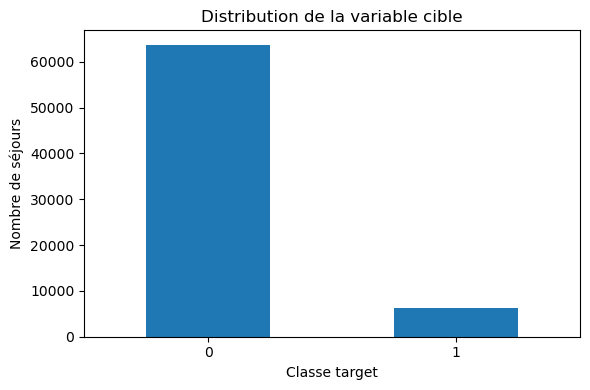

In [23]:
target = "target"

print("Valeurs de target :")
print(df[target].value_counts().sort_index())

print("\nProportions :")
display(df[target].value_counts(normalize=True).sort_index().rename("proportion").to_frame())

plt.figure(figsize=(6,4))
df[target].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Classe target")
plt.ylabel("Nombre de séjours")
plt.title("Distribution de la variable cible")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 4. Préparation des données

### 4.1 Vérification des valeurs manquantes et doublons

## 5. Séparation apprentissage / test

Nous utilisons une séparation **80 % entraînement / 20 % test** avec `stratify=y`.

La stratification est importante ici car la classe 1 est minoritaire : elle permet de conserver approximativement la même proportion de classes dans les deux ensembles.

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Train :", X_train.shape)
print("Test  :", X_test.shape)

print("\nProportion de la classe 1 :")
print(f"Train : {y_train.mean():.2%}")
print(f"Test  : {y_test.mean():.2%}")

Train : (55988, 106)
Test  : (13998, 106)

Proportion de la classe 1 :
Train : 8.98%
Test  : 8.98%


## 6. Prétraitement pour KNN

KNN repose sur des distances entre observations. Les variables doivent donc être mises sur des échelles comparables.

Nous utilisons `StandardScaler` **uniquement sur l'ensemble d'entraînement**. Le scaler est ensuite appliqué au test sans recalculer ses paramètres : cela évite une fuite de données.

Pour le Decision Tree, la normalisation n'est pas nécessaire, car les arbres effectuent des séparations par seuils.

In [25]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Normalisation terminée.")
print("Train scaled :", X_train_scaled.shape)
print("Test scaled  :", X_test_scaled.shape)

Normalisation terminée.
Train scaled : (55988, 106)
Test scaled  : (13998, 106)


## 7. Modèle 1 — KNN

Nous cherchons un nombre de voisins raisonnable. Pour limiter le coût de calcul du KNN sur près de 70 000 observations, la recherche des hyperparamètres est effectuée sur un **sous-échantillon stratifié de l'entraînement**.

Ensuite, le meilleur modèle est réentraîné sur l'ensemble `train`.

In [26]:
# Sous-échantillon stratifié pour le réglage du KNN
MAX_TUNING_SAMPLES = min(20000, len(X_train))

if len(X_train) > MAX_TUNING_SAMPLES:
    X_knn_tune, _, y_knn_tune, _ = train_test_split(
        X_train_scaled, y_train,
        train_size=MAX_TUNING_SAMPLES,
        random_state=42,
        stratify=y_train
    )
else:
    X_knn_tune, y_knn_tune = X_train_scaled, y_train

print("Échantillon utilisé pour le réglage KNN :", X_knn_tune.shape)

knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid={
        "n_neighbors": [3, 5, 7, 11],
        "weights": ["uniform", "distance"],
        "metric": ["euclidean"]
    },
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

knn_grid.fit(X_knn_tune, y_knn_tune)

print("Meilleurs paramètres KNN :", knn_grid.best_params_)
print(f"Meilleur F1 CV : {knn_grid.best_score_:.4f}")

Échantillon utilisé pour le réglage KNN : (20000, 106)
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Meilleurs paramètres KNN : {'metric': 'euclidean', 'n_neighbors': 3, 'weights': 'distance'}
Meilleur F1 CV : 0.0637


In [27]:
# Entraînement final KNN sur tout le train normalisé
knn = KNeighborsClassifier(
    **knn_grid.best_params_,
    n_jobs=-1
)

knn.fit(X_train_scaled, y_train)

y_pred_knn = knn.predict(X_test_scaled)
y_proba_knn = knn.predict_proba(X_test_scaled)[:, 1]

print("KNN entraîné.")

KNN entraîné.


## 8. Modèle 2 — Decision Tree

Pour tenir compte du déséquilibre des classes, nous utilisons `class_weight="balanced"`.

Une recherche simple d'hyperparamètres permet de contrôler la complexité de l'arbre et de limiter le surapprentissage.

In [28]:
tree_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),
    param_grid={
        "max_depth": [5, 10, 15, 20, None],
        "min_samples_leaf": [1, 5, 10, 20]
    },
    scoring="f1",
    cv=3,
    n_jobs=-1,
    verbose=1
)

tree_grid.fit(X_train, y_train)

print("Meilleurs paramètres Decision Tree :", tree_grid.best_params_)
print(f"Meilleur F1 CV : {tree_grid.best_score_:.4f}")

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Meilleurs paramètres Decision Tree : {'max_depth': 5, 'min_samples_leaf': 5}
Meilleur F1 CV : 0.2093


In [29]:
tree = tree_grid.best_estimator_

y_pred_tree = tree.predict(X_test)
y_proba_tree = tree.predict_proba(X_test)[:, 1]

print("Decision Tree entraîné.")

Decision Tree entraîné.


## 9. Fonction d'évaluation

Nous utilisons plusieurs métriques :

- **Accuracy** : proportion globale de prédictions correctes.
- **Precision** : parmi les patients prédits positifs, proportion réellement positive.
- **Recall** : parmi les vrais positifs, proportion détectée par le modèle.
- **F1-score** : compromis entre precision et recall.
- **ROC-AUC** : capacité globale de discrimination entre les classes.
- **PR-AUC** (`average_precision`) : particulièrement informative lorsque la classe positive est minoritaire.
- **Matrice de confusion** : détail des vrais/faux positifs et négatifs.

In [30]:
def evaluate_model(name, y_true, y_pred, y_proba):
    return {
        "Modèle": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba)
    }

results = pd.DataFrame([
    evaluate_model("KNN", y_test, y_pred_knn, y_proba_knn),
    evaluate_model("Decision Tree", y_test, y_pred_tree, y_proba_tree)
])

display(results.style.format({
    "Accuracy": "{:.3f}",
    "Precision": "{:.3f}",
    "Recall": "{:.3f}",
    "F1-score": "{:.3f}",
    "ROC-AUC": "{:.3f}",
    "PR-AUC": "{:.3f}"
}))

,Modèle,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,KNN,0.894,0.176,0.049,0.077,0.540,0.106
1,Decision Tree,0.573,0.123,0.609,0.204,0.633,0.151


## 10. Rapports de classification

In [31]:
print("========== KNN ==========")
print(classification_report(y_test, y_pred_knn, digits=3, zero_division=0))

print("\n===== DECISION TREE =====")
print(classification_report(y_test, y_pred_tree, digits=3, zero_division=0))

========== KNN ==========
              precision    recall  f1-score   support

           0      0.912     0.977     0.944     12741
           1      0.176     0.049     0.077      1257

    accuracy                          0.894     13998
   macro avg      0.544     0.513     0.510     13998
weighted avg      0.846     0.894     0.866     13998


===== DECISION TREE =====
              precision    recall  f1-score   support

           0      0.937     0.570     0.709     12741
           1      0.123     0.609     0.204      1257

    accuracy                          0.573     13998
   macro avg      0.530     0.590     0.456     13998
weighted avg      0.864     0.573     0.663     13998



## 11. Matrices de confusion

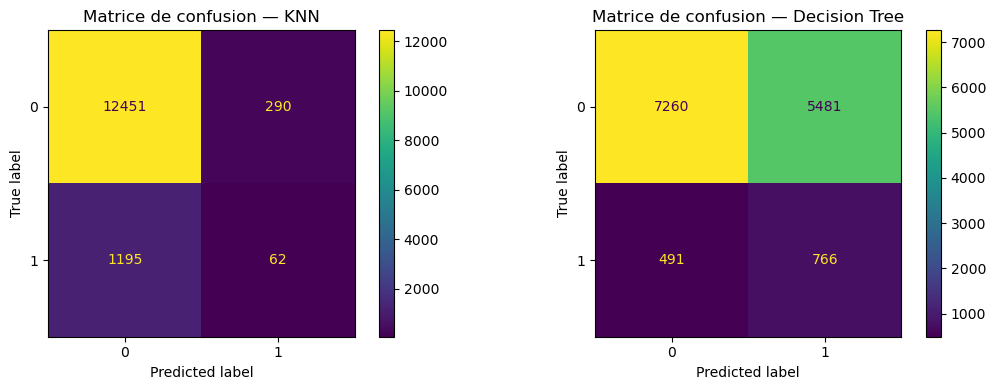

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_knn, ax=axes[0], values_format="d"
)
axes[0].set_title("Matrice de confusion — KNN")

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_tree, ax=axes[1], values_format="d"
)
axes[1].set_title("Matrice de confusion — Decision Tree")

plt.tight_layout()
plt.show()

## 12. Courbes ROC et Precision-Recall

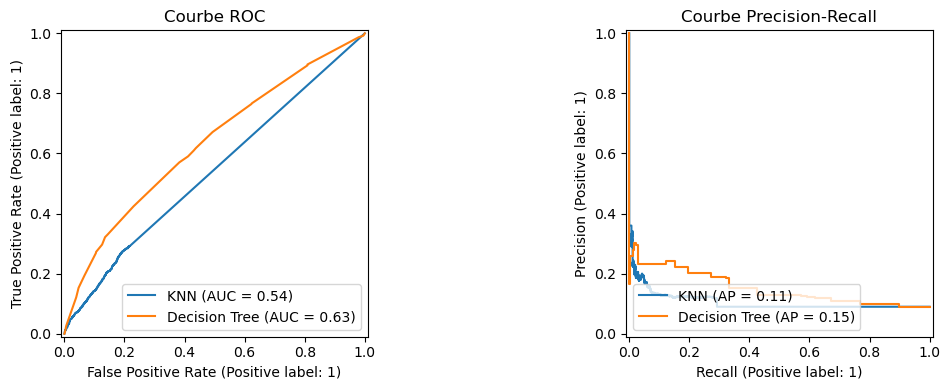

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

RocCurveDisplay.from_predictions(
    y_test, y_proba_knn, name="KNN", ax=axes[0]
)
RocCurveDisplay.from_predictions(
    y_test, y_proba_tree, name="Decision Tree", ax=axes[0]
)
axes[0].set_title("Courbe ROC")

PrecisionRecallDisplay.from_predictions(
    y_test, y_proba_knn, name="KNN", ax=axes[1]
)
PrecisionRecallDisplay.from_predictions(
    y_test, y_proba_tree, name="Decision Tree", ax=axes[1]
)
axes[1].set_title("Courbe Precision-Recall")

plt.tight_layout()
plt.show()

## 13. Interprétation du Decision Tree

L'arbre permet d'identifier les variables qui participent le plus aux décisions.

Nous affichons les principales importances des variables. Une importance élevée signifie que la variable contribue davantage aux divisions de l'arbre, mais **ne signifie pas qu'elle cause directement la réadmission**.

,importance
discharge_disposition_id_Home,0.371661
number_inpatient_log,0.229910
discharge_disposition_id_Other_hospital_rehab,0.097580
discharge_disposition_id_Care_facility,0.036718
time_in_hospital,0.032801
diag_1_groupe_Circulatory,0.031584
age,0.025706
payer_code_Missing,0.025183
diag_1_groupe_Musculoskeletal,0.024085
frequent_user,0.023310


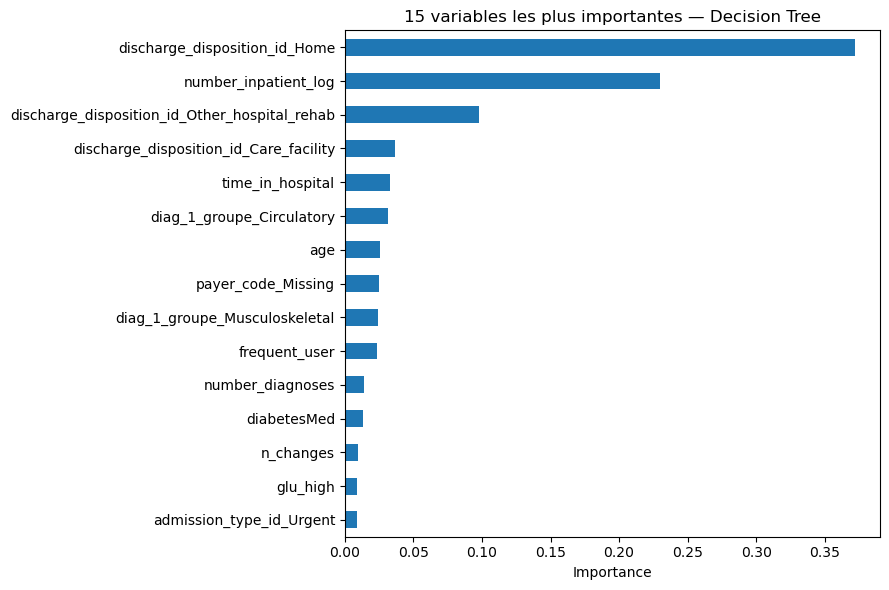

In [34]:
importances = pd.Series(
    tree.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

display(importances.head(20).to_frame("importance"))

plt.figure(figsize=(9, 6))
importances.head(15).sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("15 variables les plus importantes — Decision Tree")
plt.tight_layout()
plt.show()

## 14. Visualisation d'une partie de l'arbre

L'arbre complet peut être très grand. Nous affichons uniquement les premiers niveaux pour faciliter l'interprétation.

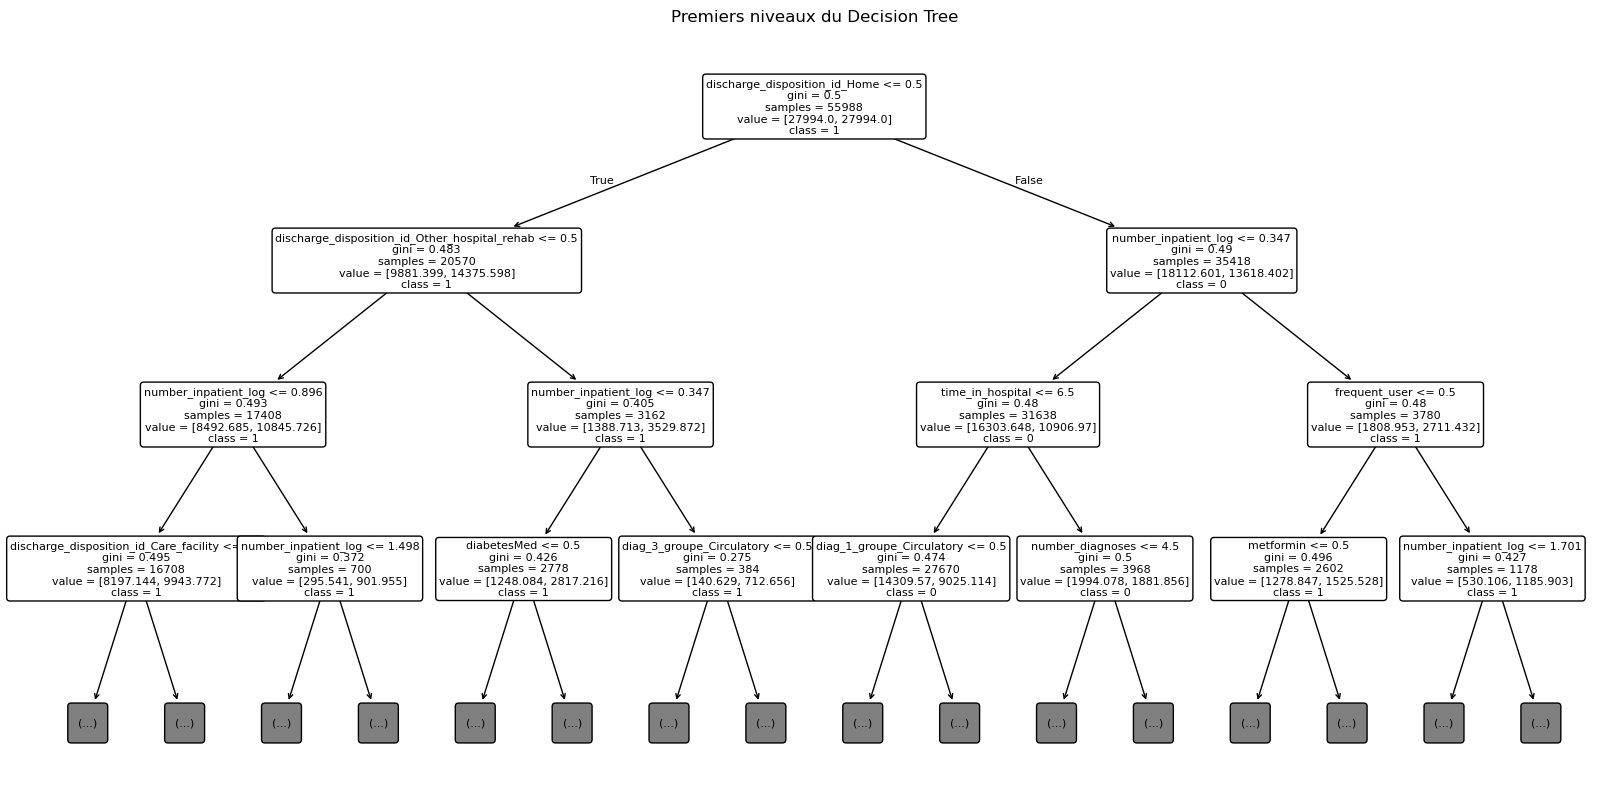

In [35]:
plt.figure(figsize=(20, 10))
plot_tree(
    tree,
    max_depth=3,
    feature_names=X.columns,
    class_names=["0", "1"],
    filled=False,
    rounded=True,
    fontsize=8
)
plt.title("Premiers niveaux du Decision Tree")
plt.show()

## 15. Comparaison et analyse des résultats

### Comment interpréter les résultats ?

Dans ce problème, la classe `1` est minoritaire. Il faut donc éviter de conclure à partir de l'accuracy uniquement.

Pour l'analyse finale :

1. Comparer **Precision, Recall et F1-score** sur la classe 1.
2. Examiner la **PR-AUC**, particulièrement adaptée au déséquilibre de classes.
3. Utiliser la **ROC-AUC** pour comparer la capacité générale de discrimination.
4. Lire les matrices de confusion pour comprendre les erreurs.
5. Pour le Decision Tree, examiner les variables importantes.

Le modèle à retenir pour une application donnée dépend de l'objectif :
- si manquer un cas positif est coûteux → accorder davantage d'importance au **Recall** ;
- si les alertes positives doivent être très fiables → accorder davantage d'importance à la **Precision** ;
- si l'on recherche un compromis → utiliser le **F1-score**.

Il ne faut donc pas déclarer un modèle « meilleur » uniquement sur une seule métrique.

In [36]:
# Tableau trié par F1 pour faciliter la lecture
display(
    results.sort_values("F1-score", ascending=False)
           .style.format({
               "Accuracy": "{:.3f}",
               "Precision": "{:.3f}",
               "Recall": "{:.3f}",
               "F1-score": "{:.3f}",
               "ROC-AUC": "{:.3f}",
               "PR-AUC": "{:.3f}"
           })
)

print("Conclusion à compléter après exécution :")
print("- Comparer le F1-score et le Recall de la classe 1.")
print("- Vérifier la PR-AUC à cause du déséquilibre.")
print("- Examiner les matrices de confusion.")
print("- Interpréter les variables importantes du Decision Tree.")

,Modèle,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
1,Decision Tree,0.573,0.123,0.609,0.204,0.633,0.151
0,KNN,0.894,0.176,0.049,0.077,0.540,0.106


Conclusion à compléter après exécution :
- Comparer le F1-score et le Recall de la classe 1.
- Vérifier la PR-AUC à cause du déséquilibre.
- Examiner les matrices de confusion.
- Interpréter les variables importantes du Decision Tree.


## 16. Conclusion

La démarche réalisée est :

**Données → nettoyage → exclusion de `target` et `cluster` → train/test stratifié → normalisation pour KNN → réglage des hyperparamètres → entraînement KNN et Decision Tree → évaluation multi-métriques → interprétation.**

Cette approche répond aux objectifs du travail :
- formulation d'une problématique de classification ;
- préparation appropriée des données ;
- application de KNN et Decision Tree ;
- utilisation de métriques adaptées ;
- analyse des erreurs et interprétation des résultats.

> **Remarque méthodologique :** le fichier fourni est déjà encodé et contient des variables dérivées (`*_log`, variables binaires et groupes diagnostiques). Le notebook utilise cette préparation existante plutôt que de réencoder les variables une deuxième fois.